# Pokémon Battle Prediction — Veriyi Anlamak

**Görev:** Her satır bir savaş. İlk 30 tur verilmiş, savaş 30–80 tur sürüyor. `player_won` = P1 sonunda kazandı mı (1/0).

**Bir satırda ne var?**

| Alan | Ne | Boyut |
|---|---|---|
| `battle_id` | savaş numarası | 1 değer |
| `p1_team_details` | P1'in **6 Pokémon'unun hepsi** (stat, tip, eşya) | 6 elemanlı liste |
| `p2_lead_details` | P2'nin **sadece ilk çıkardığı** Pokémon (eşya yok) | 1 sözlük |
| `battle_timeline` | ilk 30 tur: her turda sahadaki iki Pokémon'un durumu + kullandıkları hamle | 30 elemanlı liste |
| `player_won` | hedef (sadece train) | 0/1 |

**Asimetri:** P1'in takımını tamamen biliyoruz, P2'nin takımını sadece timeline'da sahaya çıktıkça görüyoruz.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA = "data/"
train = pd.read_json(DATA + "train.jsonl", lines=True)
test = pd.read_json(DATA + "test.jsonl", lines=True)
type_chart = pd.read_csv(DATA + "type_chart_gen2.csv")

print("train:", train.shape, " test:", test.shape)
print("P1 kazanma oranı:", train.player_won.mean())

train: (10000, 5)  test: (5000, 4)
P1 kazanma oranı: 0.5


## 1. Tek bir savaşa yakından bakış
Ham JSON'un nasıl göründüğü — savaş 0.

In [2]:
b = train.iloc[0]
print("P1 TAKIMI (6 Pokémon):")
display(pd.DataFrame(b.p1_team_details))
print("P2 LEAD (1 Pokémon):")
display(pd.DataFrame([b.p2_lead_details]))
print("TIMELINE'IN İLK TURU (ham):")
print(json.dumps(b.battle_timeline[0], indent=2))
print("Sonuç player_won =", b.player_won)

P1 TAKIMI (6 Pokémon):


,name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,item
0,tyranitar,100,"[dark, rock]",100,134,110,95,100,61,leftovers
1,typhlosion,100,"[fire, notype]",78,84,78,109,85,100,mintberry
2,golem,100,"[ground, rock]",80,110,130,55,65,45,berserkgene
3,umbreon,100,"[dark, notype]",95,65,110,60,130,65,leftovers
4,alakazam,100,"[notype, psychic]",55,50,45,135,85,120,leftovers
5,raikou,100,"[electric, notype]",90,85,75,115,100,115,leftovers


P2 LEAD (1 Pokémon):


,name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
0,forretress,100,"[bug, steel]",75,90,140,60,60,40


TIMELINE'IN İLK TURU (ham):
{
  "turn": 1,
  "p1_pokemon_state": {
    "name": "tyranitar",
    "hp_pct": 1.0,
    "status": "nostatus",
    "effects": [
      "noeffect"
    ],
    "boosts": {
      "atk": 0,
      "def": 0,
      "spa": 0,
      "spd": 0,
      "spe": 0
    }
  },
  "p1_move_details": {
    "name": "earthquake",
    "type": "ground",
    "category": "physical",
    "base_power": 100,
    "accuracy": 1.0,
    "priority": 0
  },
  "p2_pokemon_state": {
    "name": "forretress",
    "hp_pct": 0.86,
    "status": "nostatus",
    "effects": [
      "noeffect"
    ],
    "boosts": {
      "atk": 0,
      "def": 0,
      "spa": 0,
      "spd": 0,
      "spe": 0
    }
  },
  "p2_move_details": {
    "name": "toxic",
    "type": "poison",
    "category": "status",
    "base_power": 0,
    "accuracy": 0.85,
    "priority": 0
  }
}
Sonuç player_won = 0


## 2. Veriyi düz tablolara açmak
İç içe yapıyı 3 ayrı "long" tabloya açıyoruz. Analizi bunlarla yapıp, sonra `battle_id` ile tek satıra indireceğiz.

- `p1_team` → savaş × Pokémon (10.000 × 6 = 60.000 satır)
- `p2_lead` → savaş başına 1 satır
- `turns` → savaş × tur (10.000 × 30 = 300.000 satır)

In [3]:
def explode_team(df):
    t = df[["battle_id", "p1_team_details"]].explode("p1_team_details", ignore_index=True)
    out = pd.json_normalize(t["p1_team_details"])
    out.insert(0, "battle_id", t["battle_id"].values)
    out["slot"] = out.groupby("battle_id").cumcount()
    out["type1"] = out["types"].str[0]
    out["type2"] = out["types"].str[1].fillna("none")
    return out

def lead_table(df):
    out = pd.json_normalize(df["p2_lead_details"])
    out.insert(0, "battle_id", df["battle_id"].values)
    return out

def turns_table(df):
    t = df[["battle_id", "battle_timeline"]].explode("battle_timeline", ignore_index=True)
    out = pd.json_normalize(t["battle_timeline"])
    out.insert(0, "battle_id", t["battle_id"].values)
    # move alanı null olan satırlarda json_normalize sütunları NaN bırakır
    return out

p1_team = explode_team(train)
p2_lead = lead_table(train)
turns = turns_table(train)

print(p1_team.shape, p2_lead.shape, turns.shape)
display(p1_team.head(6))
display(p2_lead.head(3))

(60000, 14) (10000, 10) (300000, 34)


,battle_id,name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,item,slot,type1,type2
0,0,tyranitar,100,"[dark, rock]",100,134,110,95,100,61,leftovers,0,dark,rock
1,0,typhlosion,100,"[fire, notype]",78,84,78,109,85,100,mintberry,1,fire,notype
2,0,golem,100,"[ground, rock]",80,110,130,55,65,45,berserkgene,2,ground,rock
3,0,umbreon,100,"[dark, notype]",95,65,110,60,130,65,leftovers,3,dark,notype
4,0,alakazam,100,"[notype, psychic]",55,50,45,135,85,120,leftovers,4,notype,psychic
5,0,raikou,100,"[electric, notype]",90,85,75,115,100,115,leftovers,5,electric,notype


,battle_id,name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
0,0,forretress,100,"[bug, steel]",75,90,140,60,60,40
1,1,raikou,100,"[electric, notype]",90,85,75,115,100,115
2,2,exeggutor,100,"[grass, psychic]",95,95,85,125,65,55


In [4]:
print(turns.columns.tolist())
turns.head(5)

['battle_id', 'turn', 'p1_pokemon_state.name', 'p1_pokemon_state.hp_pct', 'p1_pokemon_state.status', 'p1_pokemon_state.effects', 'p1_pokemon_state.boosts.atk', 'p1_pokemon_state.boosts.def', 'p1_pokemon_state.boosts.spa', 'p1_pokemon_state.boosts.spd', 'p1_pokemon_state.boosts.spe', 'p1_move_details.name', 'p1_move_details.type', 'p1_move_details.category', 'p1_move_details.base_power', 'p1_move_details.accuracy', 'p1_move_details.priority', 'p2_pokemon_state.name', 'p2_pokemon_state.hp_pct', 'p2_pokemon_state.status', 'p2_pokemon_state.effects', 'p2_pokemon_state.boosts.atk', 'p2_pokemon_state.boosts.def', 'p2_pokemon_state.boosts.spa', 'p2_pokemon_state.boosts.spd', 'p2_pokemon_state.boosts.spe', 'p2_move_details.name', 'p2_move_details.type', 'p2_move_details.category', 'p2_move_details.base_power', 'p2_move_details.accuracy', 'p2_move_details.priority', 'p1_move_details', 'p2_move_details']


,battle_id,turn,p1_pokemon_state.name,p1_pokemon_state.hp_pct,p1_pokemon_state.status,p1_pokemon_state.effects,p1_pokemon_state.boosts.atk,p1_pokemon_state.boosts.def,p1_pokemon_state.boosts.spa,p1_pokemon_state.boosts.spd,p1_pokemon_state.boosts.spe,p1_move_details.name,p1_move_details.type,p1_move_details.category,p1_move_details.base_power,p1_move_details.accuracy,p1_move_details.priority,p2_pokemon_state.name,p2_pokemon_state.hp_pct,p2_pokemon_state.status,p2_pokemon_state.effects,p2_pokemon_state.boosts.atk,p2_pokemon_state.boosts.def,p2_pokemon_state.boosts.spa,p2_pokemon_state.boosts.spd,p2_pokemon_state.boosts.spe,p2_move_details.name,p2_move_details.type,p2_move_details.category,p2_move_details.base_power,p2_move_details.accuracy,p2_move_details.priority,p1_move_details,p2_move_details
0,0,1,tyranitar,1.00,nostatus,[noeffect],0,0,0,0,0,earthquake,ground,physical,100.0,1.00,0.0,forretress,0.86,nostatus,[noeffect],0,0,0,0,0,toxic,poison,status,0.0,0.85,0.0,NaN,NaN
1,0,2,typhlosion,1.00,tox,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,forretress,0.93,nostatus,[noeffect],0,0,0,0,0,toxic,poison,status,0.0,0.85,0.0,NaN,NaN
2,0,3,typhlosion,0.94,tox,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,zapdos,0.61,nostatus,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,4,typhlosion,0.03,tox,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,zapdos,0.26,nostatus,[noeffect],0,0,0,0,0,hiddenpower,normal,physical,0.0,1.00,0.0,NaN,NaN
4,0,5,typhlosion,1.00,nostatus,[noeffect],0,0,0,0,0,rest,psychic,status,0.0,1.00,0.0,snorlax,1.00,nostatus,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. P1 takımı

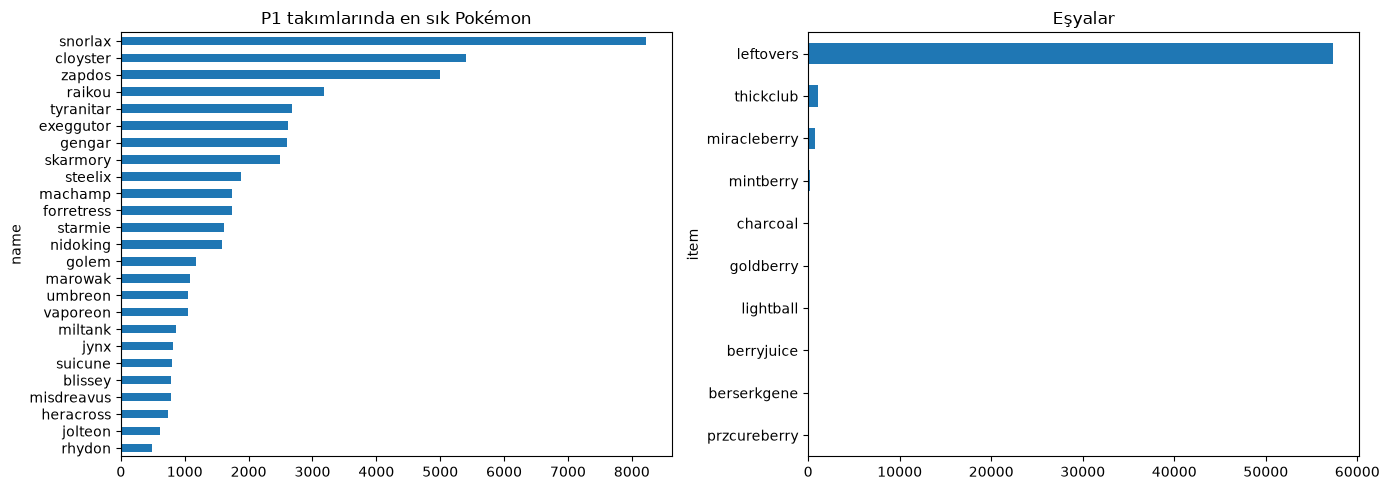

Farklı Pokémon sayısı: 237
Seviye dağılımı: {100: 59640, 5: 212, 16: 15, 58: 14, 35: 11, 15: 8, 40: 8, 65: 8, 50: 7, 10: 7, 99: 6, 55: 6, 25: 6, 62: 6, 11: 5, 31: 4, 12: 4, 44: 3, 36: 2, 27: 2, 32: 2, 14: 2, 46: 2, 9: 2, 45: 2, 56: 2, 66: 2, 17: 1, 20: 1, 54: 1, 21: 1, 26: 1, 3: 1, 7: 1, 2: 1, 24: 1, 70: 1, 68: 1, 13: 1}


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
p1_team.name.value_counts().head(25).plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("P1 takımlarında en sık Pokémon")
p1_team.item.value_counts().head(10).plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title("Eşyalar")
plt.tight_layout(); plt.show()

print("Farklı Pokémon sayısı:", p1_team.name.nunique())
print("Seviye dağılımı:", p1_team.level.value_counts().to_dict())

In [6]:
stat_cols = ["base_hp", "base_atk", "base_def", "base_spa", "base_spd", "base_spe"]
# Her Pokémon türünün stat'ı sabit — bu yüzden stat'lar aslında "isim"in bir fonksiyonu
species = p1_team.drop_duplicates("name").set_index("name")[stat_cols + ["type1", "type2"]]
species["total"] = species[stat_cols].sum(axis=1)
species.sort_values("total", ascending=False).head(20)

,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,type1,type2,total
name,,,,,,,,,
hooh,106,130,90,110,154,90,fire,flying,680
mewtwo,106,110,90,154,90,130,notype,psychic,680
gengarmega,60,65,80,170,95,130,ghost,poison,600
dragonite,91,134,95,100,100,80,dragon,flying,600
tyranitar,100,134,110,95,100,61,dark,rock,600
moltres,90,100,90,125,85,90,fire,flying,580
articuno,90,85,100,95,125,85,flying,ice,580
zapdos,90,90,85,125,90,100,electric,flying,580
raikou,90,85,75,115,100,115,electric,notype,580


### Hangi Pokémon takımda olunca P1 daha çok kazanıyor?
Takımda olma → kazanma oranı (en az 200 savaşta görülenler).

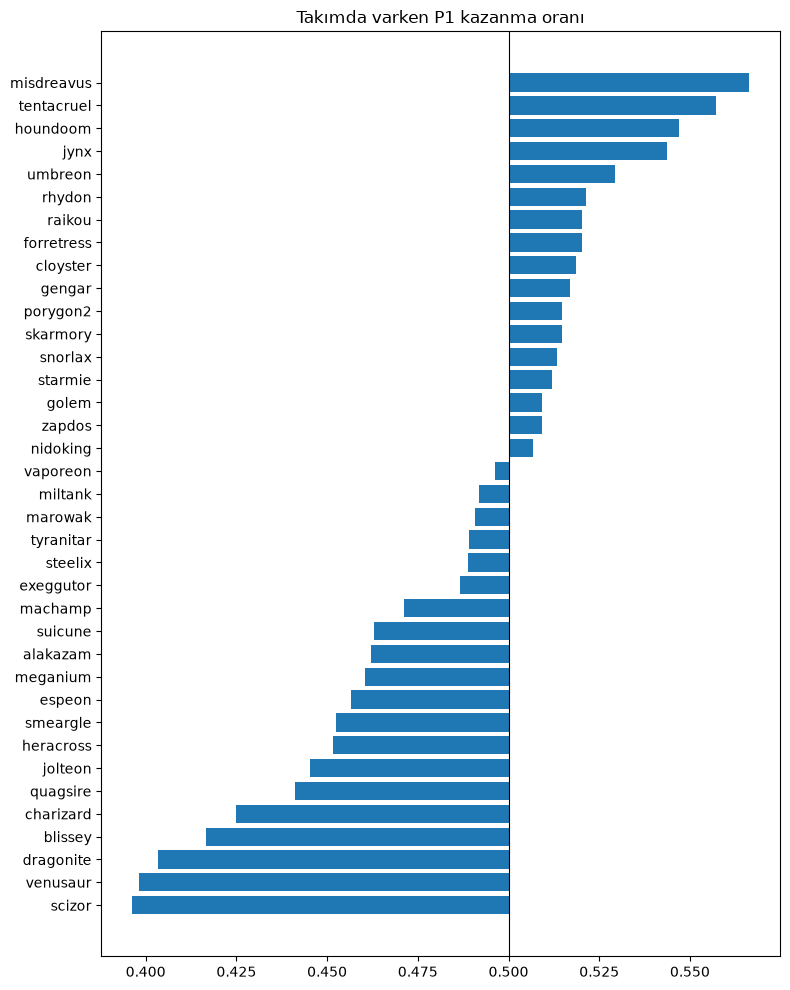

In [7]:
pw = p1_team.merge(train[["battle_id", "player_won"]], on="battle_id")
g = pw.groupby("name").player_won.agg(["mean", "count"]).query("count >= 200").sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(g.index, g["mean"] - 0.5, left=0.5)
ax.axvline(0.5, color="k", lw=0.8); ax.set_title("Takımda varken P1 kazanma oranı")
plt.tight_layout(); plt.show()

## 4. P2 lead
P2'nin ilk Pokémon'u. Timeline'ın 1. turundaki P2 Pokémon'u ile ~%69 eşleşiyor, çünkü **timeline'daki state turun sonundaki durum**: 1. turda switch yapılırsa yeni gelen Pokémon görünür ve o turun hamlesi `null` olur (eşleşmeyen 3084 savaşın hepsinde P2 hamlesi `null`).

p2_lead == turn1 P2: 0.6916
P1 takımının 1. elemanı == turn1 P1: 0.7018


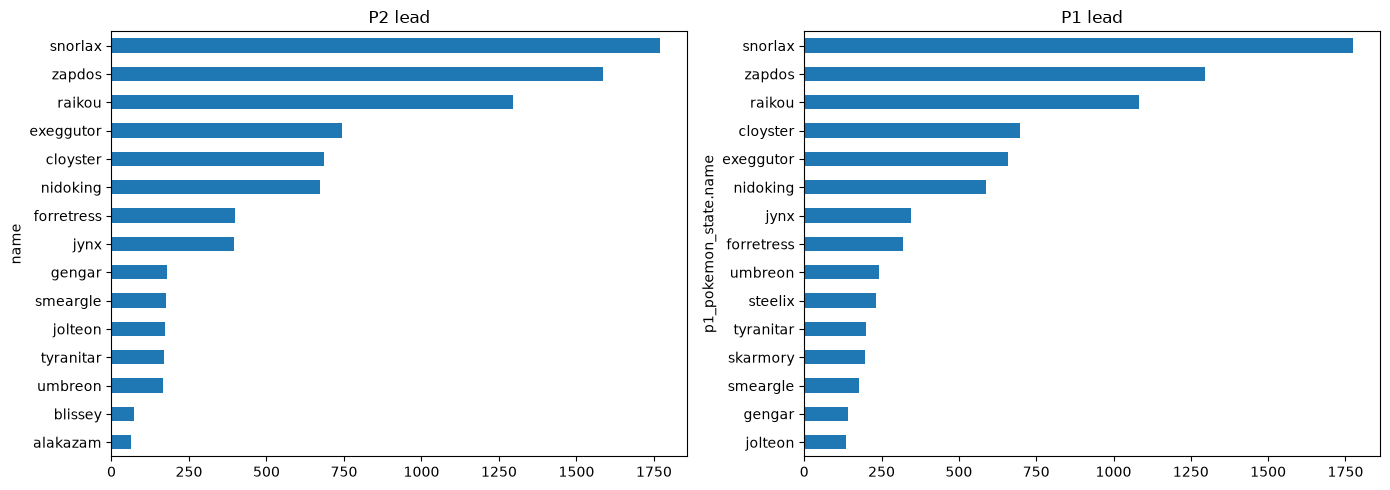

In [8]:
first = turns[turns.turn == 1].set_index("battle_id")
print("p2_lead == turn1 P2:", (first["p2_pokemon_state.name"] == p2_lead.set_index("battle_id").name).mean())
print("P1 takımının 1. elemanı == turn1 P1:", (first["p1_pokemon_state.name"] == p1_team[p1_team.slot == 0].set_index("battle_id").name).mean())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
p2_lead.name.value_counts().head(15).plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("P2 lead")
first["p1_pokemon_state.name"].value_counts().head(15).plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title("P1 lead")
plt.tight_layout(); plt.show()

## 5. Timeline — asıl bilgi burada
Bir savaşın 30 turunu okunur şekilde gösterelim. `move` boş (`NaN`) = o tur hamle yapılmadı (switch, uyku, felç, bayılma).

In [9]:
def show_battle(bid):
    t = turns[turns.battle_id == bid]
    view = pd.DataFrame({
        "turn": t["turn"],
        "p1": t["p1_pokemon_state.name"], "p1_hp": t["p1_pokemon_state.hp_pct"], "p1_status": t["p1_pokemon_state.status"],
        "p1_move": t["p1_move_details.name"],
        "p2": t["p2_pokemon_state.name"], "p2_hp": t["p2_pokemon_state.hp_pct"], "p2_status": t["p2_pokemon_state.status"],
        "p2_move": t["p2_move_details.name"],
    })
    return view.set_index("turn")

show_battle(0)

,p1,p1_hp,p1_status,p1_move,p2,p2_hp,p2_status,p2_move
turn,,,,,,,,
1,tyranitar,1.00,nostatus,earthquake,forretress,0.86,nostatus,toxic
2,typhlosion,1.00,tox,NaN,forretress,0.93,nostatus,toxic
3,typhlosion,0.94,tox,fireblast,zapdos,0.61,nostatus,NaN
4,typhlosion,0.03,tox,fireblast,zapdos,0.26,nostatus,hiddenpower
5,typhlosion,1.00,nostatus,rest,snorlax,1.00,nostatus,NaN
6,typhlosion,1.00,nostatus,thunderpunch,snorlax,0.94,nostatus,curse
7,typhlosion,1.00,nostatus,fireblast,snorlax,0.75,nostatus,curse
8,typhlosion,0.02,nostatus,fireblast,snorlax,0.36,nostatus,doubleedge
9,typhlosion,0.02,nostatus,fireblast,snorlax,1.00,slp,rest


### Durumlar (status), etkiler (effects), boost'lar
`fnt` = bayıldı. `slp` uyku, `par` felç, `tox`/`psn` zehir, `frz` donma, `brn` yanık.

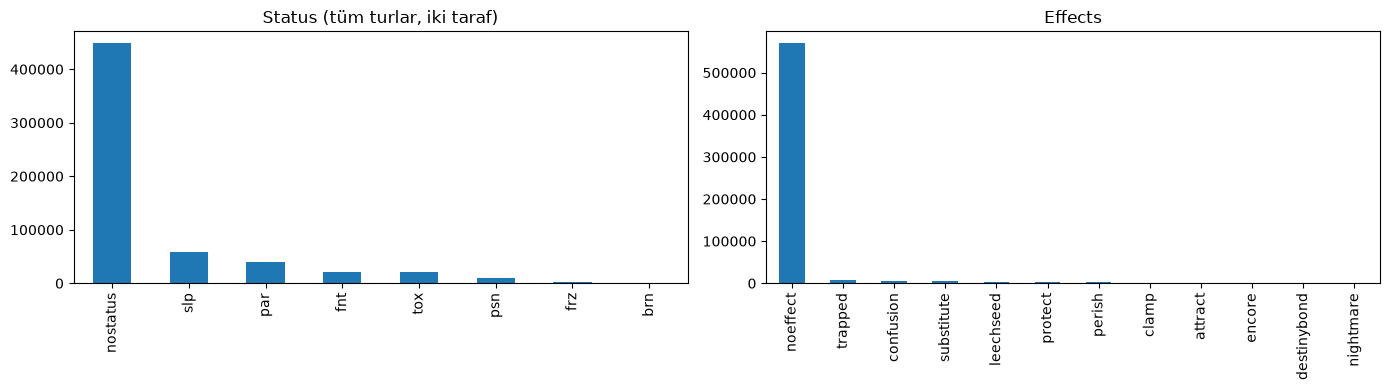

,mean,min,max
p1_pokemon_state.boosts.atk,0.155913,-6.0,6.0
p1_pokemon_state.boosts.def,0.133667,-5.0,6.0
p1_pokemon_state.boosts.spa,0.015960,0.0,6.0
p1_pokemon_state.boosts.spd,-0.002397,-2.0,6.0
p1_pokemon_state.boosts.spe,-0.118247,-6.0,6.0
p2_pokemon_state.boosts.atk,0.162563,-6.0,6.0
p2_pokemon_state.boosts.def,0.139307,-6.0,6.0
p2_pokemon_state.boosts.spa,0.013710,0.0,6.0
p2_pokemon_state.boosts.spd,-0.002417,-3.0,6.0
p2_pokemon_state.boosts.spe,-0.127647,-6.0,6.0


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pd.concat([turns["p1_pokemon_state.status"], turns["p2_pokemon_state.status"]]).value_counts().plot.bar(ax=ax[0], title="Status (tüm turlar, iki taraf)")
pd.concat([turns["p1_pokemon_state.effects"], turns["p2_pokemon_state.effects"]]).explode().value_counts().head(12).plot.bar(ax=ax[1], title="Effects")
plt.tight_layout(); plt.show()

boost_cols = [c for c in turns.columns if "boosts" in c]
turns[boost_cols].describe().T[["mean", "min", "max"]]

### Hamleler

Hamle yapılmayan tur oranı: 0.198


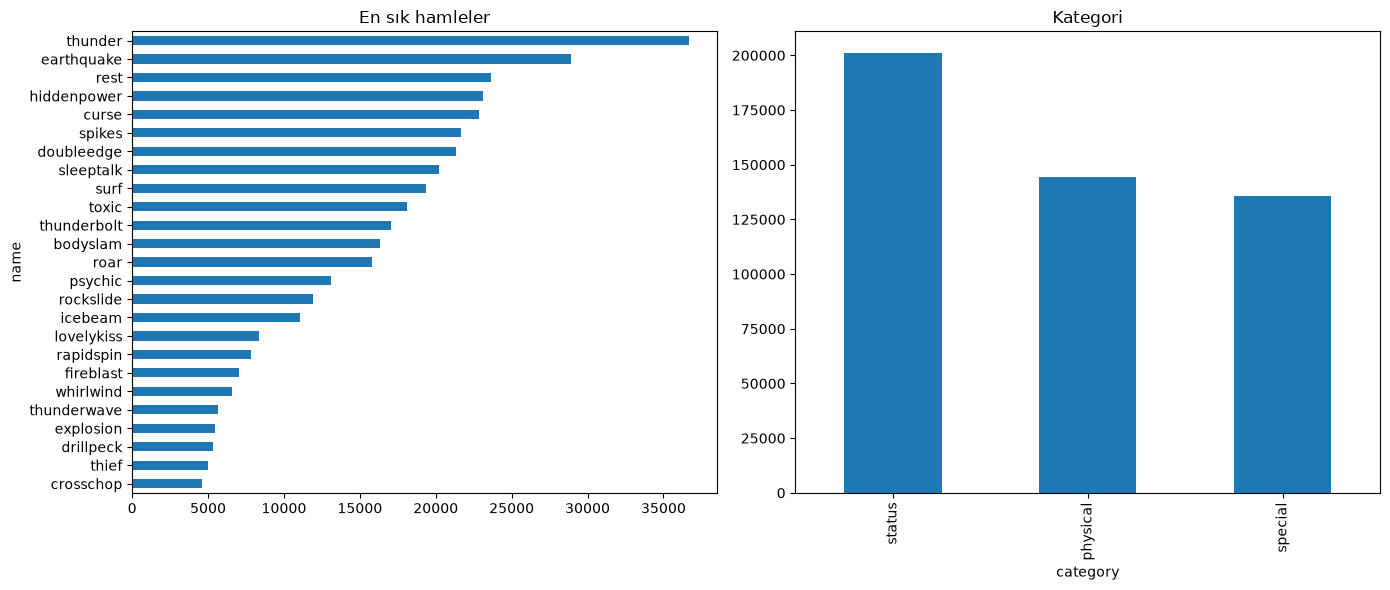

In [11]:
moves = pd.concat([
    turns.filter(like="p1_move_details.").rename(columns=lambda c: c.split(".")[-1]),
    turns.filter(like="p2_move_details.").rename(columns=lambda c: c.split(".")[-1]),
])
print("Hamle yapılmayan tur oranı:", moves.name.isna().mean().round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
moves.name.value_counts().head(25).plot.barh(ax=ax[0]); ax[0].invert_yaxis(); ax[0].set_title("En sık hamleler")
moves.category.value_counts().plot.bar(ax=ax[1], title="Kategori")
plt.tight_layout(); plt.show()

## 6. 30. turdaki durumu özetlemek
Her Pokémon için **son görüldüğü** HP ve status'u alırsak, 30. turda tablonun nasıl olduğunu görürüz.

- P1: 6 Pokémon'u biliyoruz; hiç sahaya çıkmayanlar %100 HP.
- P2: sadece görülenleri biliyoruz; görülmeyenler (6 − görülen) muhtemelen %100 HP.

In [12]:
def side_state(turns, side):
    cols = {f"{side}_pokemon_state.name": "name", f"{side}_pokemon_state.hp_pct": "hp", f"{side}_pokemon_state.status": "status"}
    s = turns[["battle_id", "turn", *cols]].rename(columns=cols)
    last = s.sort_values("turn").groupby(["battle_id", "name"]).last()
    agg = last.groupby("battle_id").agg(
        seen=("hp", "size"),
        fainted=("status", lambda x: (x == "fnt").sum()),
        statused=("status", lambda x: x.isin(["slp", "par", "tox", "psn", "frz", "brn"]).sum()),
        hp_seen=("hp", "sum"),
    )
    agg["hp_total"] = agg["hp_seen"] + (6 - agg["seen"])  # görülmeyenler tam can varsayımı
    agg["switches"] = s.groupby("battle_id")["name"].apply(lambda x: (x != x.shift()).sum() - 1)
    return agg.add_prefix(f"{side}_")

state = pd.concat([side_state(turns, "p1"), side_state(turns, "p2")], axis=1).reset_index()
state = state.merge(train[["battle_id", "player_won"]], on="battle_id")
state["fainted_diff"] = state.p2_fainted - state.p1_fainted   # + ise P1 önde
state["hp_diff"] = state.p1_hp_total - state.p2_hp_total
state.describe().T

,count,mean,std,min,25%,50%,75%,max
battle_id,10000.0,4999.500000,2886.895680,0.00000,2499.750000,4999.500000,7499.250000,9999.0
p1_seen,10000.0,5.409500,0.768159,1.00000,5.000000,6.000000,6.000000,6.0
p1_fainted,10000.0,1.688200,1.431428,0.00000,1.000000,1.000000,3.000000,6.0
p1_statused,10000.0,1.038600,0.913999,0.00000,0.000000,1.000000,2.000000,5.0
p1_hp_seen,10000.0,2.838902,1.253780,0.00000,1.940000,2.850000,3.750188,6.0
p1_hp_total,10000.0,3.429402,1.333362,0.00000,2.522484,3.530000,4.450000,6.0
p1_switches,10000.0,10.276300,3.153467,0.00000,8.000000,10.000000,12.000000,26.0
p2_seen,10000.0,5.390000,0.792946,1.00000,5.000000,6.000000,6.000000,6.0
p2_fainted,10000.0,0.504000,0.774496,0.00000,0.000000,0.000000,1.000000,5.0
p2_statused,10000.0,1.350700,0.995293,0.00000,1.000000,1.000000,2.000000,6.0


### Bu özetler sonucu ne kadar açıklıyor?

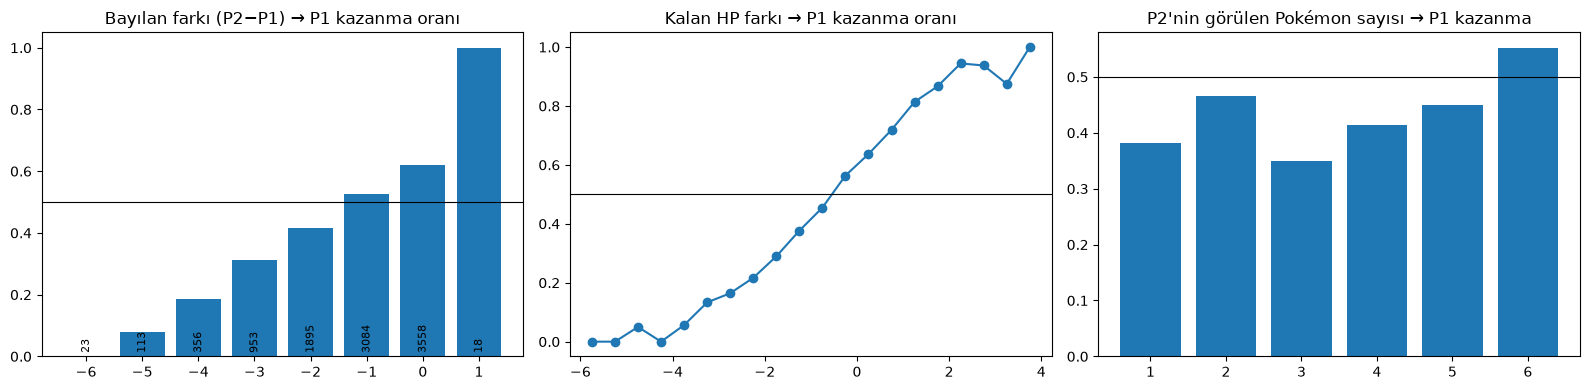

Sadece 'hp_diff > 0 ise P1 kazanır' kuralının doğruluğu: 0.6312
Sadece 'fainted_diff > 0 ise P1 kazanır' (eşitse 0.5): 0.5443


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
g = state.groupby("fainted_diff").player_won.agg(["mean", "count"])
ax[0].bar(g.index, g["mean"]); ax[0].set_title("Bayılan farkı (P2−P1) → P1 kazanma oranı"); ax[0].axhline(0.5, color="k", lw=0.8)
for k, v in g["count"].items(): ax[0].text(k, 0.02, int(v), ha="center", fontsize=8, rotation=90)

state["hp_bin"] = pd.cut(state.hp_diff, bins=np.arange(-6, 6.5, 0.5))
g = state.groupby("hp_bin", observed=True).player_won.mean()
ax[1].plot([i.mid for i in g.index], g.values, marker="o"); ax[1].axhline(0.5, color="k", lw=0.8); ax[1].set_title("Kalan HP farkı → P1 kazanma oranı")

g = state.groupby("p2_seen").player_won.mean()
ax[2].bar(g.index, g.values); ax[2].axhline(0.5, color="k", lw=0.8); ax[2].set_title("P2'nin görülen Pokémon sayısı → P1 kazanma")
plt.tight_layout(); plt.show()

print("Sadece 'hp_diff > 0 ise P1 kazanır' kuralının doğruluğu:", ((state.hp_diff > 0) == state.player_won).mean().round(4))
print("Sadece 'fainted_diff > 0 ise P1 kazanır' (eşitse 0.5):",
      np.where(state.fainted_diff == 0, 0.5, (state.fainted_diff > 0) == state.player_won).mean().round(4))

### Zaman içinde: HP farkı tur tur nasıl açılıyor?
Kazanan ve kaybeden savaşlarda ortalama "aktif Pokémon HP farkı".

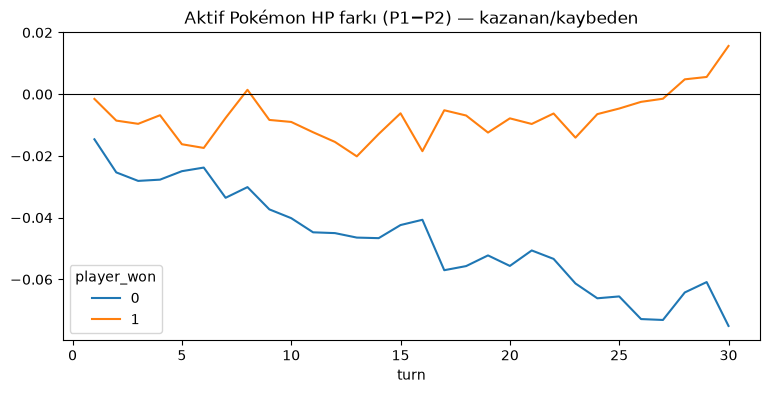

In [14]:
t = turns[["battle_id", "turn", "p1_pokemon_state.hp_pct", "p2_pokemon_state.hp_pct"]].merge(train[["battle_id", "player_won"]], on="battle_id")
t["d"] = t["p1_pokemon_state.hp_pct"] - t["p2_pokemon_state.hp_pct"]
t.groupby(["turn", "player_won"]).d.mean().unstack().plot(figsize=(9, 4), title="Aktif Pokémon HP farkı (P1−P2) — kazanan/kaybeden")
plt.axhline(0, color="k", lw=0.8); plt.show()

## 7. Tip tablosu
`multiplier`: saldıran tip → savunan tip. Tabloda olmayan çiftler = 1.0. Çift tipli savunanda çarpanlar çarpılır.

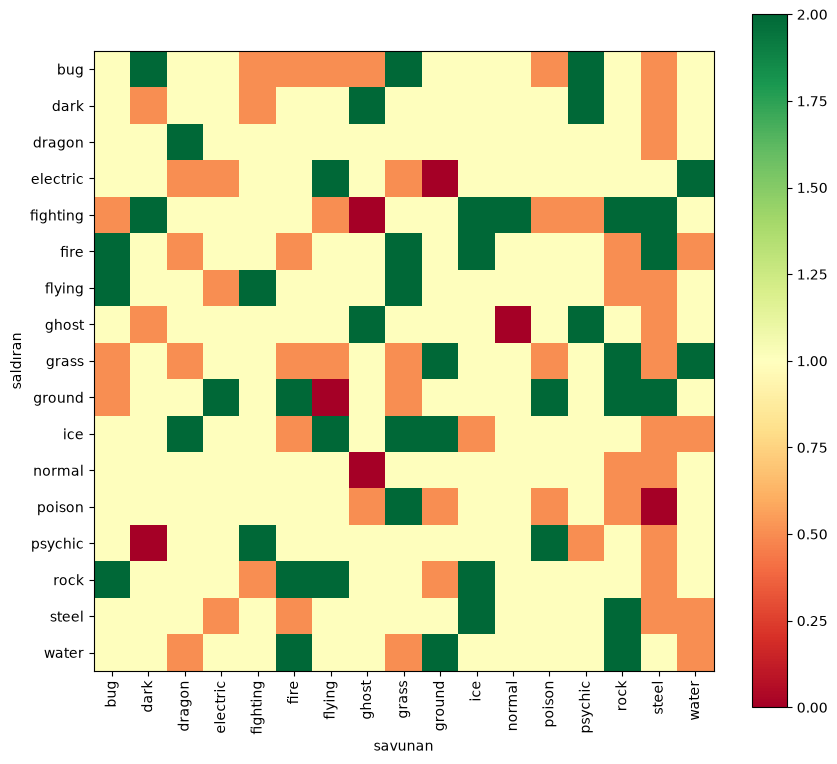

water → [fire, rock]: 4.0


In [15]:
types = sorted(set(type_chart.attacking_type) | set(type_chart.defending_type))
chart = type_chart.pivot(index="attacking_type", columns="defending_type", values="multiplier").reindex(index=types, columns=types).fillna(1.0)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(chart.values, cmap="RdYlGn", vmin=0, vmax=2)
ax.set_xticks(range(len(types)), types, rotation=90); ax.set_yticks(range(len(types)), types)
ax.set_xlabel("savunan"); ax.set_ylabel("saldıran"); plt.colorbar(im); plt.show()

def effectiveness(atk_type, def_types):
    m = 1.0
    for d in def_types:
        if d and d != "none":
            m *= chart.loc[atk_type, d]
    return m

print("water → [fire, rock]:", effectiveness("water", ["fire", "rock"]))

## 8. Train ve test benzer mi?

,train,test
p1_seen,5.410,5.418
p1_fainted,1.688,1.684
p1_statused,1.039,1.037
p1_hp_seen,2.839,2.856
p1_hp_total,3.429,3.437
p1_switches,10.276,10.324
p2_seen,5.390,5.391
p2_fainted,0.504,0.513
p2_statused,1.351,1.347
p2_hp_seen,3.386,3.387


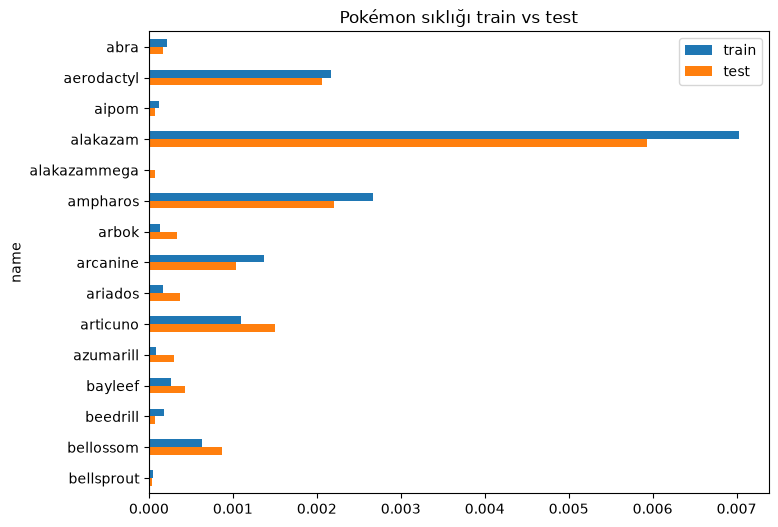

In [16]:
turns_te = turns_table(test)
state_te = pd.concat([side_state(turns_te, "p1"), side_state(turns_te, "p2")], axis=1)
cmp = pd.DataFrame({"train": state.drop(columns=["battle_id", "player_won", "hp_bin", "fainted_diff", "hp_diff"]).mean(),
                    "test": state_te.mean()})
display(cmp.round(3))

p1_te = explode_team(test)
top = pd.DataFrame({"train": p1_team.name.value_counts(normalize=True), "test": p1_te.name.value_counts(normalize=True)}).head(15)
top.plot.barh(figsize=(8, 6), title="Pokémon sıklığı train vs test").invert_yaxis(); plt.show()

## 9. Hızlı sinyal testi (5-fold CV)
Sadece yukarıdaki birkaç özetle basit bir model ne kadar gidiyor — sonraki adımların çıkış noktası.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

X = state.drop(columns=["battle_id", "player_won", "hp_bin"])
y = state.player_won
cv = StratifiedKFold(5, shuffle=True, random_state=42)

for name, m in [("LogReg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
                ("HistGB", HistGradientBoostingClassifier(random_state=42))]:
    s = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    print(f"{name}: {s.mean():.4f} ± {s.std():.4f}")

LogReg: 0.6626 ± 0.0057


HistGB: 0.6547 ± 0.0064


## 10. Özet: Özellik fikirleri (öncelik sırasıyla)

Benzer Pokémon tahmin çalışmalarında en güçlü sinyal **iki tarafın kalan toplam HP'si / bayılan Pokémon sayısı** çıkıyor; tur bazlı özellikler takım stat'larından çok daha güçlü.

1. **30. tur durumu** (bölüm 6): bayılan sayıları, kalan HP toplamı, status'lu Pokémon sayısı (özellikle `slp`, `par`, `frz` — Gen 2'de çok etkili), farklar.
2. **Gidişat**: son 5/10 turdaki HP değişimi, ilk bayılmayı kim yaptı, turn 10/20/30'daki farklar.
3. **P2 hakkında bilgi**: görülen Pokémon sayısı ve isimleri (multi-hot), görülmeyenlerin sayısı.
4. **Boost'lar ve etkiler**: son turdaki boost toplamı (Curse/Belly Drum Snorlax, Swords Dance), `substitute`, `leechseed`, `perish`.
5. **Hamle bazlı**: verilen hasar (HP düşüşü), super-effective vuruş sayısı (tip tablosu), status hamlesi oranı, priority hamleler.
6. **Takım bilgisi**: P1 takımında belirli Pokémon'lar (multi-hot), tip sayıları, stat ortalamaları; P1 takımının P2'nin görülen Pokémon'larına karşı tip avantajı.
7. **Sahadaki son matchup**: 30. turda sahadaki iki Pokémon, HP'leri, hız karşılaştırması.

**Validation:** `StratifiedKFold(5)`; tüm özellik/model kararlarını CV ortalamasıyla ver, leaderboard'u sadece kontrol için kullan. Model: önce LogisticRegression (baseline) → gradient boosting (LightGBM/XGBoost/HistGB) → ensemble.